# 18 — Beam-matched ring TODs for every survey and sky model

**Why.** Until now every map was turned into a TRIS ring TOD with `sed_prototype.Inputs._native_tod`: the map, at its
**own resolution**, degraded to nside 16 and observed with limTOD's measured TRIS beam on an nside-16 grid. That is a
convolution with the TRIS beam, but **not beam matching**: each survey's own beam (LWA1 35 MHz 4.65°, Maipu 4.6°,
LWA1 80 MHz 2.04°, LFSM 5.1°, …) stays in the TOD on top of the TRIS beam, and the sky is pixelised at nside 16
(3.7° pixels) before the beam is applied. The TRIS data themselves see the sky through the TRIS beam only.

**What this notebook does.** It makes ring TODs with the **pipeline's own beam matching**: stage 2's `tris_cuts`
kernel (`moonrunes.elliptical_beam`, `PIPELINE.md` Appendix A.9), evaluated directly at the 120 ring pointings.

* **Kernel:** the measured TRIS cut beam (19.155° × 23.366°, E plane 7° east of the meridian, zero beyond 90°).
  For a survey whose own beam would widen the TRIS core by more than 0.2% (natives above ~1.2°), the cut beam is
  compressed to the quadrature widths √(TRIS² − native²), so that after the survey's own beam the total is the TRIS
  beam (`broad_native_kernel: scaled_cuts`). Narrower natives use the cut beam as is.
* **Pointings:** TRIS is a zenith-pointing drift scan, so ring sample k sees RA = LST_k, Dec = 42.433° (limTOD's
  `tris_zenith_geometry`).
* **Sky grid:** the map is put on nside 64 (0.92° pixels, `beam_matching.elliptical.nside_work`), 4× finer than the
  old TOD route; partial maps use the normalised convolution, and a sample is kept when the observed-weight fraction
  is ≥ 0.5 (`beam_matching.weight_floor`), the same floor as the old coverage cut.
* **Maps:** every fitted survey and Haslam at their own frequency; the seven 408 MHz sky models of notebook 12; and
  GSM2008 and GSM2016 at the TRIS effective frequencies (600.5, 817.8 MHz).
* **Corrections stretched to the TRIS frequencies:** the Carter and Irfan corrections are defined at 408 MHz and GINAN
  at 350 MHz, so they cannot be applied at 600/820 MHz directly. Each is applied to the base model's 408 MHz map
  (GSM2008 or GSM2016; GINAN to GSM2016 as in notebook 12), and the corrected map is carried to 600.5 / 817.8 MHz
  with the base model's own per-pixel spectrum: T_corr(ν) = T_corr(408) × T_model(ν) / T_model(408). This keeps
  each model's spectral shape and scales the correction with it; it is an assumption, not part of the published
  corrections. Applying Carter (a Haslam calibration) to GSM2008 is natural because GSM2008 is locked to Haslam at
  408 MHz; for GSM2016 it is a test of the same idea.
* **LFSM stretched to the TRIS frequencies:** LFSM is only valid up to 408 MHz and has no spectrum above it, so it is
  extended as a power law with its own per-pixel spectral index between 300 and 408 MHz:
  T(ν) = T(408) (ν/408)^β, β = ln[T(408)/T(300)] / ln(408/300). Also an assumption. Temperatures are converted exactly as for
  the SED fit (`sky_maps.rj_excess`: RJ, CMB removed).

**Outputs** go to `model_comparison/beam_matched_tods/`: the TODs (`beam_matched_tods.npz` and a CSV), the native
beams used, and a comparison with the old TODs. Notebooks 14 (T–T and TRIS-frequency TODs) read them.
**Switched everywhere (2026-10-27):** `sed_prototype.Inputs.ring_tod` now makes exactly these TODs
(`run_config.yaml` `sed.tod_beam: beam_matched`; checked equal to the cache here to 0 K), so the SED fits
(`run_comparison.py`) and notebooks 07, 08, 10–17 use them once rerun (see the last cell). The old TODs this
notebook compares against are kept in `old_native_tods.npz`.

Rerun: Restart & Run All (a few minutes; the result is cached).

In [1]:
%matplotlib inline
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUT_DIR = REPO / "model_comparison" / "beam_matched_tods"
OLD_CACHE = REPO / "model_comparison" / "sky_models_408" / "cache"        # notebook 12, read only (ring RA)
OLD_SNAPSHOT = REPO / "model_comparison" / "beam_matched_tods" / "old_native_tods.npz"   # the old TODs, saved 2026-10-27
HASLAM_FILE = "HASLAM_DESTRIPED_ONLY.fits"
REBUILD = False            # True: recompute even if the cache matches

# Native beams of the sky models (FWHM, deg).  Surveys take theirs from the file metadata (sky_maps.discover).
MODEL_NATIVE_FWHM = {
    "Haslam (uncorrected)": 56 / 60,         # the Haslam map's own 56'
    "Haslam, Carter correction": 56 / 60,    # a scale and offset of Haslam: same beam
    "Haslam, Irfan correction": 56 / 60,
    "GSM2008": 1.0,                          # pygdsm GSM2008, basemap 'haslam': ~1 deg (pygdsm docstring)
    "GSM2016": 0.8,                          # pygdsm GSM2016 'hi': 48' below 10 GHz (pygdsm docstring)
    "GSM2016, GINAN correction": 0.8,        # a correction of GSM2016: same beam
    "LFSM": 5.1,                             # LWA1 LFSM project page: 5.1 deg
}
CARTER = dict(scale=1.029, offset_k=0.91)    # Carter et al. 2025: on the CMB-removed map (notebook 12)
IRFAN_MONOPOLE_K = 8.9                       # Irfan & Puglisi 2025 (notebook 12)
GINAN_FREQ_MHZ = 350.0                       # McKay et al. 2025, top of the valid range (notebook 12)
LFSM_BETA_FROM_MHZ = 300.0                   # LFSM stretched above 408 MHz with its own beta between this and 408 MHz
NU_TRIS = {"TRIS_600": 600.5, "TRIS_820": 817.8}
CYG_A_RA = 299.9

plt.rcParams.update({"figure.dpi": 110, "font.size": 12, "axes.titlesize": 13, "axes.labelsize": 12,
                     "legend.fontsize": 10, "figure.facecolor": "white"})
OUT_DIR.mkdir(exist_ok=True)

def save(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"saved {(OUT_DIR / f'{name}.png').relative_to(REPO)}")

## The beam-matched observation

`ring_tod(sky, observed, frame, native_fwhm)` rotates a map to equatorial (as `Inputs._rotated` does), and evaluates
the pipeline's beam-matching kernel for that native beam at the 120 ring pointings. The table lists the kernel chosen
for each native width.

In [2]:
sys.dont_write_bytecode = True
sys.path.insert(0, str(REPO / "src"))
import healpy as hp
from moonrunes import frames, sky_maps, elliptical_beam
from moonrunes.config import load_config
from moonrunes.stage1_tris_maps import import_limtod_tris

config = load_config(REPO / "configs" / "run_config.yaml")
SPEC = elliptical_beam.beam_spec_from_config(config, kernel="tris_cuts")
FLOOR = float(config.require("beam_matching.weight_floor"))
tris = import_limtod_tris(config)
RA = np.load(OLD_CACHE / "ring_RA.npy")
geom = tris.tris_zenith_geometry(RA)
assert np.allclose(geom.elevation_deg, 90.0) and np.allclose(geom.lst_deg, RA)
DEC = float(geom.latitude_deg)
VEC = hp.ang2vec(np.radians(90.0 - DEC) * np.ones_like(RA), np.radians(RA))
print(f"{RA.size} pointings at Dec {DEC:.3f} deg, RA = LST 0-357 deg; kernel spec: tris_cuts, "
      f"E {SPEC.fwhm_e_deg} x H {SPEC.fwhm_h_deg} deg, nside_work {SPEC.nside_work}, weight floor {FLOOR}")

def to_equatorial(sky, observed, frame):
    if frame == "C":
        return sky, observed
    if observed.all():
        return frames.rotate_full_sky(sky, (frame, "C")), observed
    rot, obs, _ = frames.rotate_masked(sky, observed, (frame, "C"))
    return rot, obs

def ring_tod(sky, observed, frame, native_fwhm):
    sky = np.asarray(sky, dtype=float); observed = np.asarray(observed, dtype=bool)
    eq, obs = to_equatorial(np.where(observed, sky, 0.0), observed, frame)
    r = elliptical_beam.smooth_at_positions(np.where(obs, eq, 0.0), obs, native_fwhm, SPEC, VEC)
    return np.asarray(r["values"], float), np.asarray(r["weight"], float), r["kernel"]

rows = []
for n in sorted({0.24, 0.33, 0.59, 0.8, 0.933, 1.0, 2.04, 4.6, 4.65, 5.1}):
    k = elliptical_beam.kernel_for(SPEC, n)
    rows.append({"native FWHM [deg]": n, "kernel": k.shape, "kernel E x H [deg]": f"{k.fwhm_e_deg:.2f} x {k.fwhm_h_deg:.2f}",
                 "expected total E x H [deg]": f"{k.expected_e_deg:.2f} x {k.expected_h_deg:.2f}"})
print(pd.DataFrame(rows).to_string(index=False))

120 pointings at Dec 42.433 deg, RA = LST 0-357 deg; kernel spec: tris_cuts, E 19.155 x H 23.366 deg, nside_work 64, weight floor 0.5
 native FWHM [deg]    kernel kernel E x H [deg] expected total E x H [deg]
             0.240 tris_cuts      19.16 x 23.37              19.16 x 23.37
             0.330 tris_cuts      19.16 x 23.37              19.16 x 23.37
             0.590 tris_cuts      19.16 x 23.37              19.16 x 23.37
             0.800 tris_cuts      19.16 x 23.37              19.17 x 23.38
             0.933 tris_cuts      19.16 x 23.37              19.18 x 23.38
             1.000 tris_cuts      19.16 x 23.37              19.18 x 23.39
             2.040 tris_cuts      19.05 x 23.28              19.16 x 23.37
             4.600 tris_cuts      18.59 x 22.91              19.16 x 23.37
             4.650 tris_cuts      18.58 x 22.90              19.16 x 23.37
             5.100 tris_cuts      18.46 x 22.80              19.16 x 23.37


## Build the TODs (cached)

In [3]:
from moonrunes.sed_prototype import NU0_MHZ
CACHE = OUT_DIR / "beam_matched_tods.npz"
KEY = OUT_DIR / "beam_matched_tods_key.json"
key = json.dumps({"spec": [SPEC.kernel, SPEC.fwhm_e_deg, SPEC.fwhm_h_deg, SPEC.nside_work, SPEC.eval_subdivision,
                           SPEC.broad_native_kernel, SPEC.max_broadening_fraction], "dec": DEC, "floor": FLOOR,
                  "models": MODEL_NATIVE_FWHM, "carter": CARTER, "irfan": IRFAN_MONOPOLE_K, "ginan": GINAN_FREQ_MHZ,
                  "nu_tris": NU_TRIS, "stretched_corrections": 1, "lfsm_beta_from": LFSM_BETA_FROM_MHZ}, sort_keys=True)

def build():
    out, meta = {}, []
    maps = {m["file"]: m for m in sky_maps.discover(REPO / "res")}
    excluded = list(config.get_path("sed.exclude_maps", []) or [])
    surveys = [m for m in maps.values() if m["usable"] and m["role"] == "fit" and m["file"] not in excluded]
    surveys.append(maps[HASLAM_FILE])
    for m in surveys:
        obs = np.isfinite(m["sky"])
        tod, w, k = ring_tod(m["sky"], obs, m["frame"], float(m["fwhm_deg"]))
        t = np.where(w >= FLOOR, np.asarray(sky_maps.rj_excess(tod, m), float), np.nan)
        out[f"survey::{m['file']}"] = t; out[f"weight::survey::{m['file']}"] = w
        meta.append(dict(kind="survey", name=m["file"], freq_mhz=float(m["freq_mhz"]), native_fwhm_deg=float(m["fwhm_deg"]),
                         kernel=k.shape, kernel_e_deg=k.fwhm_e_deg, kernel_h_deg=k.fwhm_h_deg,
                         n_valid=int(np.isfinite(t).sum())))
        print(f"  {m['file']:<30} native {m['fwhm_deg']:.2f} deg -> {k.shape} {k.fwhm_e_deg:.2f} x {k.fwhm_h_deg:.2f}; "
              f"{int(np.isfinite(t).sum())} samples")

    # 408 MHz sky models (CMB-removed RJ), as notebook 12 builds them
    from pygdsm import GlobalSkyModel, GlobalSkyModel16, LowFrequencySkyModel
    from pygdsm.mckay25 import generate_mckay25_correction, T_CMB
    h = maps[HASLAM_FILE]
    e_h = np.asarray(sky_maps.rj_excess(h["sky"], h), float)
    cmb408 = float(sky_maps.cmb_rj_k(408.0))
    g16 = GlobalSkyModel16(freq_unit="MHz", data_unit="TRJ", include_cmb=False)
    g16_408 = np.array(g16.generate(408.0), float)
    g16_lo = np.array(g16.generate(GINAN_FREQ_MHZ), float)
    off, scl = generate_mckay25_correction(np.array([GINAN_FREQ_MHZ / 1e3]))
    g16_cmb = np.array(GlobalSkyModel16(freq_unit="MHz", data_unit="TCMB", include_cmb=True).generate(GINAN_FREQ_MHZ), float)
    models408 = {
        "Haslam (uncorrected)": (e_h, h["frame"]),
        "Haslam, Carter correction": (CARTER["scale"] * e_h + CARTER["offset_k"], h["frame"]),
        "Haslam, Irfan correction": (e_h - (IRFAN_MONOPOLE_K - cmb408), h["frame"]),
        "GSM2008": (np.array(GlobalSkyModel(freq_unit="MHz", include_cmb=False).generate(408.0), float), "G"),
        "GSM2016": (g16_408, "G"),
        "GSM2016, GINAN correction": (((g16_cmb - off[0]) * scl[0] - T_CMB) * g16_408 / g16_lo, "G"),
        "LFSM": (np.array(LowFrequencySkyModel(freq_unit="MHz", include_cmb=False).generate(408.0), float), "G"),
    }
    for name, (sky, fr) in models408.items():
        tod, w, k = ring_tod(sky, np.isfinite(sky), fr, MODEL_NATIVE_FWHM[name])
        out[f"model408::{name}"] = np.where(w >= FLOOR, tod, np.nan); out[f"weight::model408::{name}"] = w
        meta.append(dict(kind="model 408", name=name, freq_mhz=408.0, native_fwhm_deg=MODEL_NATIVE_FWHM[name],
                         kernel=k.shape, kernel_e_deg=k.fwhm_e_deg, kernel_h_deg=k.fwhm_h_deg,
                         n_valid=int(np.isfinite(out[f'model408::{name}']).sum())))
    # GSM2008 / GSM2016 at the TRIS effective frequencies (CMB-removed RJ), and the 408 MHz corrections
    # "stretched" there: the corrected 408 MHz map times the base model's own per-pixel ratio T(nu)/T(408).
    g08_408 = np.array(GlobalSkyModel(freq_unit="MHz", include_cmb=False).generate(408.0), float)
    base408 = {"GSM2008": g08_408, "GSM2016": g16_408}
    corrected408 = {
        ("GSM2008", "Carter correction"): CARTER["scale"] * g08_408 + CARTER["offset_k"],
        ("GSM2008", "Irfan correction"): g08_408 - (IRFAN_MONOPOLE_K - cmb408),
        ("GSM2016", "Carter correction"): CARTER["scale"] * g16_408 + CARTER["offset_k"],
        ("GSM2016", "Irfan correction"): g16_408 - (IRFAN_MONOPOLE_K - cmb408),
        ("GSM2016", "GINAN correction"): models408["GSM2016, GINAN correction"][0],
    }
    # LFSM stops at 408 MHz: stretch it with its own per-pixel spectral index between LFSM_BETA_FROM_MHZ and 408 MHz,
    # T(nu) = T(408) (nu/408)^beta, beta = ln(T408/T_lo) / ln(408/lo).
    lfsm = LowFrequencySkyModel(freq_unit="MHz", include_cmb=False)
    lfsm_408 = np.array(lfsm.generate(408.0), float)
    lfsm_lo = np.array(lfsm.generate(LFSM_BETA_FROM_MHZ), float)
    lfsm_beta = np.log(lfsm_408 / lfsm_lo) / np.log(408.0 / LFSM_BETA_FROM_MHZ)
    print(f"  LFSM beta {LFSM_BETA_FROM_MHZ:g}-408 MHz: median {np.nanmedian(lfsm_beta):.3f}, "
          f"5-95% {np.nanpercentile(lfsm_beta, 5):.3f} to {np.nanpercentile(lfsm_beta, 95):.3f}")
    for key_t, nu in NU_TRIS.items():
        at_nu = {"GSM2008": np.array(GlobalSkyModel(freq_unit="MHz", include_cmb=False).generate(nu), float),
                 "GSM2016": np.array(g16.generate(nu), float)}
        skies = dict(at_nu)
        for (base, corr), m408 in corrected408.items():
            skies[f"{base}, {corr}"] = m408 * at_nu[base] / base408[base]
        skies["LFSM, stretched"] = lfsm_408 * (nu / 408.0) ** lfsm_beta
        for name, sky in skies.items():
            native = MODEL_NATIVE_FWHM[name.split(",")[0]]
            tod, w, k = ring_tod(sky, np.ones(len(sky), bool), "G", native)
            out[f"modeltris::{name}::{key_t}"] = np.where(w >= FLOOR, tod, np.nan)
            meta.append(dict(kind=f"model {key_t}", name=name, freq_mhz=nu, native_fwhm_deg=native,
                             kernel=k.shape, kernel_e_deg=k.fwhm_e_deg, kernel_h_deg=k.fwhm_h_deg,
                             n_valid=int(np.isfinite(out[f'modeltris::{name}::{key_t}']).sum())))
    return out, pd.DataFrame(meta)

if CACHE.exists() and KEY.exists() and KEY.read_text() == key and not REBUILD:
    z = np.load(CACHE, allow_pickle=False); BM = {k: z[k] for k in z.files}
    META = pd.read_csv(OUT_DIR / "beam_matched_tods_meta.csv")
    print("beam-matched TODs loaded from the cache")
else:
    print("building beam-matched TODs (a few minutes)...")
    BM, META = build()
    np.savez(CACHE, ra_deg=RA, **BM)
    BM["ra_deg"] = RA
    META.to_csv(OUT_DIR / "beam_matched_tods_meta.csv", index=False)
    KEY.write_text(key)
    long = pd.DataFrame({"ra_deg": RA, **{k: v for k, v in BM.items() if not k.startswith("weight::") and k != "ra_deg"}})
    long.to_csv(OUT_DIR / "beam_matched_tods.csv", index=False)
    print(f"saved {CACHE.relative_to(REPO)}, beam_matched_tods.csv and beam_matched_tods_meta.csv")
print(META.round(3).to_string(index=False))

beam-matched TODs loaded from the cache
          kind                        name  freq_mhz  native_fwhm_deg    kernel  kernel_e_deg  kernel_h_deg  n_valid
        survey              LWA_35MHz.fits      35.0            4.650 tris_cuts        18.582        22.899      120
        survey            MAIPU_45mhZ.fits      45.0            4.600 tris_cuts        18.594        22.909      120
        survey              LWA_80MHz.fits      80.0            2.040 tris_cuts        19.046        23.277      120
        survey        CHIPASS_1400MHz.fits    1400.0            0.240 tris_cuts        19.155        23.366        0
        survey STOCKERT_VILLA_1400MHZ.fits    1420.0            0.590 tris_cuts        19.155        23.366      120
        survey RHODES_HARTRAO_2326MHz.fits    2326.0            0.333 tris_cuts        19.155        23.366        0
        survey  HASLAM_DESTRIPED_ONLY.fits     408.0            0.933 tris_cuts        19.155        23.366      120
     model 408        Ha

## How much does beam matching change the TODs?

The beam-matched TOD minus the old TOD (`Inputs._native_tod`), in kelvin, per ring sample: the median, the median of
the absolute value and the largest absolute value. The old TODs are the fit inputs of notebook 12's power-law fits,
its 408 MHz sky-model TODs and notebook 14's GSM TODs at the TRIS frequencies, as they were before the switch; they
were saved to `old_native_tods.npz` on 2026-10-27, because rerunning notebooks 12 and 14 replaces those caches.

In [4]:
# The old TODs, as notebook 12's fit cache, its sky_tods.npz and notebook 14's GSM cache held them before
# the switch (rerunning those notebooks replaces them with the beam-matched ones).
zo = np.load(OLD_SNAPSHOT, allow_pickle=False)
assert np.allclose(zo["ra_deg"], RA)
old = {k: zo[k] for k in zo.files if k != "ra_deg"}

NATIVE_OF = META.groupby("name")["native_fwhm_deg"].first().to_dict()
rows = []
for k in [k for k in BM if not k.startswith("weight::") and k != "ra_deg"]:
    if k not in old:
        continue
    d = BM[k] - old[k]
    ok = np.isfinite(d)
    rows.append({"TOD": k.split("::", 1)[1].replace("::", " at "), "kind": k.split("::")[0],
                 "native FWHM [deg]": float(NATIVE_OF[k.split("::")[1]]),
                 "N": int(ok.sum()), "median new − old [K]": np.median(d[ok]),
                 "median |new − old| [K]": np.median(np.abs(d[ok])), "largest |new − old| [K]": np.abs(d[ok]).max(),
                 "RA of largest [deg]": RA[ok][np.argmax(np.abs(d[ok]))]})
CMP = pd.DataFrame(rows)
CMP.to_csv(OUT_DIR / "beam_matched_minus_old.csv", index=False)
with pd.option_context("display.width", 220):
    print(CMP.round(3).to_string(index=False))

                        TOD      kind  native FWHM [deg]   N  median new − old [K]  median |new − old| [K]  largest |new − old| [K]  RA of largest [deg]
             LWA_35MHz.fits    survey              4.650 120               -30.169                  41.927                  263.759               302.75
           MAIPU_45mhZ.fits    survey              4.600 120               -17.256                  23.701                  105.259               302.75
             LWA_80MHz.fits    survey              2.040 120                -1.926                   2.290                   18.304               302.75
STOCKERT_VILLA_1400MHZ.fits    survey              0.590 120                -0.000                   0.001                    0.010               305.75
 HASLAM_DESTRIPED_ONLY.fits    survey              0.933 120                -0.018                   0.021                    0.237               300.00
       Haslam (uncorrected)  model408              0.933 120                -0.018

### Figure 1 — beam-matched minus old TOD along the ring
Each line is one TOD: the beam-matched ring TOD minus the old one, in kelvin. Left: the surveys used in the SED fit
and Haslam; right: the 408 MHz sky models. The dotted line is Cygnus A.

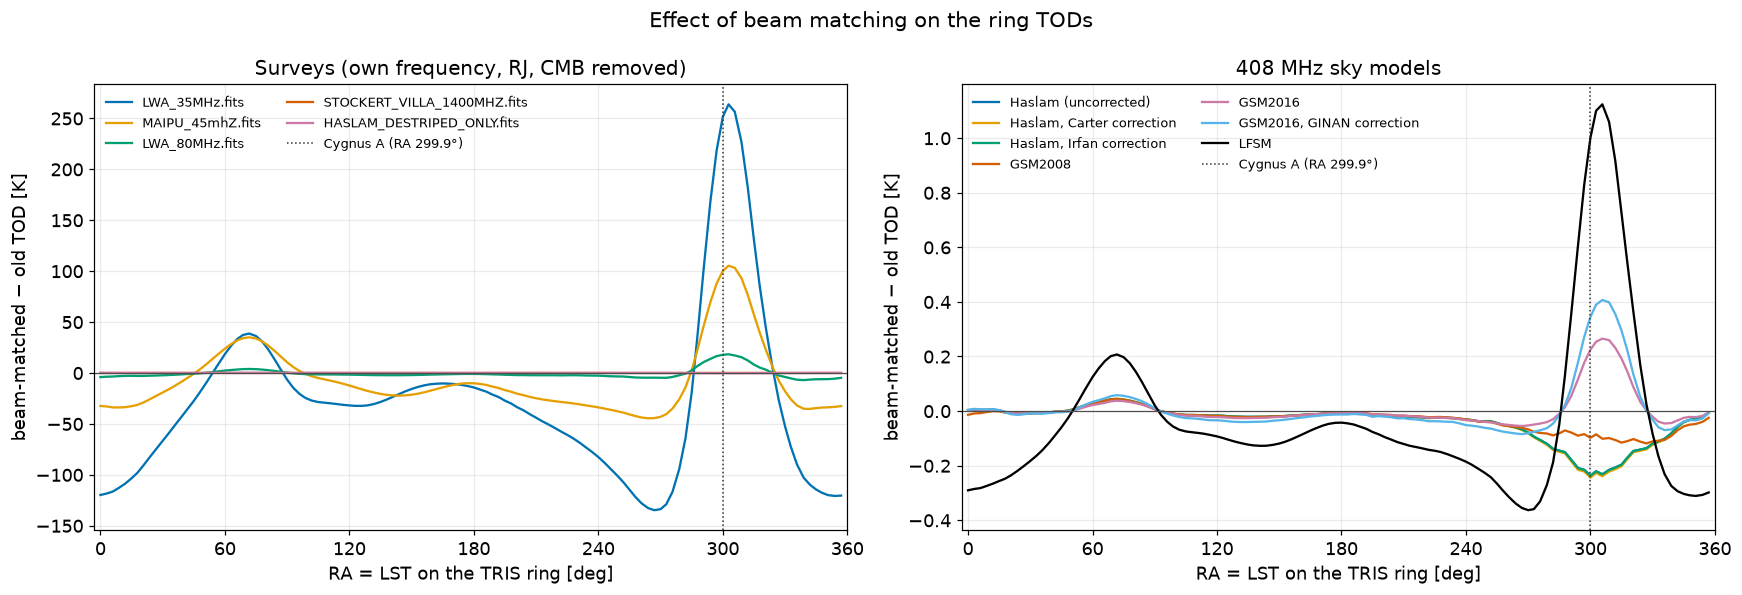

saved model_comparison/beam_matched_tods/fig1_beam_matched_minus_old.png


In [5]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 5.5), sharex=True)
cols = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9", "#000000", "#882255"]
for ax, kind in ((a1, "survey"), (a2, "model408")):
    keys = [k for k in BM if k.startswith(kind + "::") and k in old]
    for c, k in zip(cols, keys):
        ax.plot(RA, BM[k] - old[k], color=c, lw=1.5, label=k.split("::")[1])
    ax.axhline(0, color="0.3", lw=0.8)
    ax.axvline(CYG_A_RA, color="0.2", ls=":", lw=1, label=f"Cygnus A (RA {CYG_A_RA:g}°)")
    ax.set_xlim(-3, 360); ax.set_xticks(np.arange(0, 361, 60)); ax.grid(alpha=0.25)
    ax.set_xlabel("RA = LST on the TRIS ring [deg]"); ax.set_ylabel("beam-matched − old TOD [K]")
    ax.legend(frameon=False, fontsize=8.5, ncol=2)
a1.set_title("Surveys (own frequency, RJ, CMB removed)"); a2.set_title("408 MHz sky models")
fig.suptitle("Effect of beam matching on the ring TODs", fontsize=14)
fig.tight_layout()
save(fig, "fig1_beam_matched_minus_old")

## Where the beam-matched TODs are used

Since 2026-10-27 the pipeline's own TOD code makes these TODs: `sed_prototype.Inputs.ring_tod`, set by
`run_config.yaml` `sed.tod_beam: beam_matched` (the older route is `sed.tod_beam: native`). Its TODs equal this
notebook's cache to 0 K, with the same valid samples, for every survey and Haslam.

* **Read from this notebook's cache:** notebook 14 (T–T β, the β matrix and the TRIS-frequency TODs).
* **Made by `Inputs.ring_tod`:** the SED fits behind `model_comparison/results/` (`run_comparison.py`), notebook 12's
  fit cache and 408 MHz sky-model TODs (and so notebooks 13, 15, 16 and 17, which read them), notebook 11, and notebooks
  07, 08 and 10. Their caches carry a `tod_key`, so fits made from the old TODs are redone, not reused.
* **Not changed:** notebooks 01, 03, 09 and `beam_averaging_blobs/`, which study the TRIS beam itself with limTOD, and
  the map route and stage 2, which smooth with `beam_matching.kernel`.
